## Water Levels at Banagher Bridge, River Shannon

In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
from datetime import datetime

colour_pal = sns.color_palette()
# https://waterlevel.ie/hydro-data/#/overview/Waterlevel/station/11617/Banagher/Qdownload
## correct for height above malin head
height = 30.330 # this is height of sensor 25017 above Malin Head
#df['DayMin'] = df['DayMin'] - height
'''
I want to calculate the floodline here, 
## Suggest last thursday is 3 feet above flood. - Dec 2023, check data for exact date!
Find scalar for flood level in M. 
also import mean and percentile values from the waterlevels website, and compare them.
'''

#importing the datasets
# this dataset has one datapoint for each day.
df = pd.read_csv('25017_banagher_s_complete.csv', skiprows=12).iloc[:, :-1] # for now exclude the quality column

df = df.set_index('Day') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df.index = pd.to_datetime(df.index, format='mixed', dayfirst=True)
#df['Value'] = df['Value'] - height # to recalibrate water level # this might need a different col name

# this dataset has the hourly readouts.
df = pd.read_csv('tsvalues.csv', sep=';', skiprows=10).iloc[:, :-1] # drop the water quality for now

df = df.set_index('#Timestamp') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df.index = pd.to_datetime(df.index, format='mixed', dayfirst=True)
df['Value'] = df['Value'] - height # to recalibrate water level, keep colname value for now.


In [100]:
df.head()
df.tail()
#df.index

,Value
#Timestamp,
2024-03-13 23:30:00+00:00,2.994
2024-03-13 23:45:00+00:00,2.994
2024-03-14 00:00:00+00:00,2.995
2024-03-14 00:15:00+00:00,2.996
2024-03-14 00:30:00+00:00,2.995


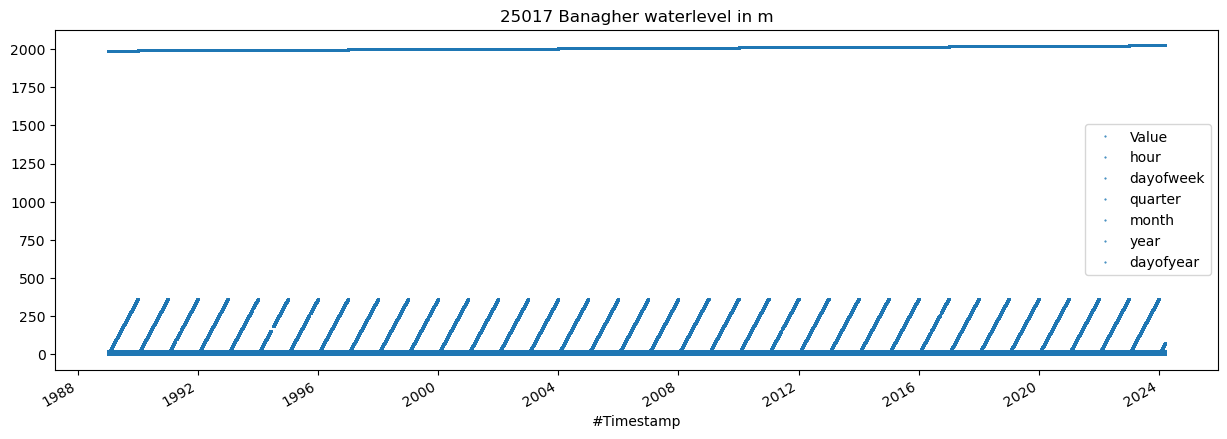

In [121]:
df.plot(style='.', 
        figsize=(15,5), 
        color=colour_pal[0], 
        title='25017 Banagher waterlevel in m',
        markersize=1)
plt.show()
# issues here with zeros on the first plot but I will come to fix this.

In [40]:
#df.index

## Train / Test Split

In [42]:
# later I will change this to full cross validation

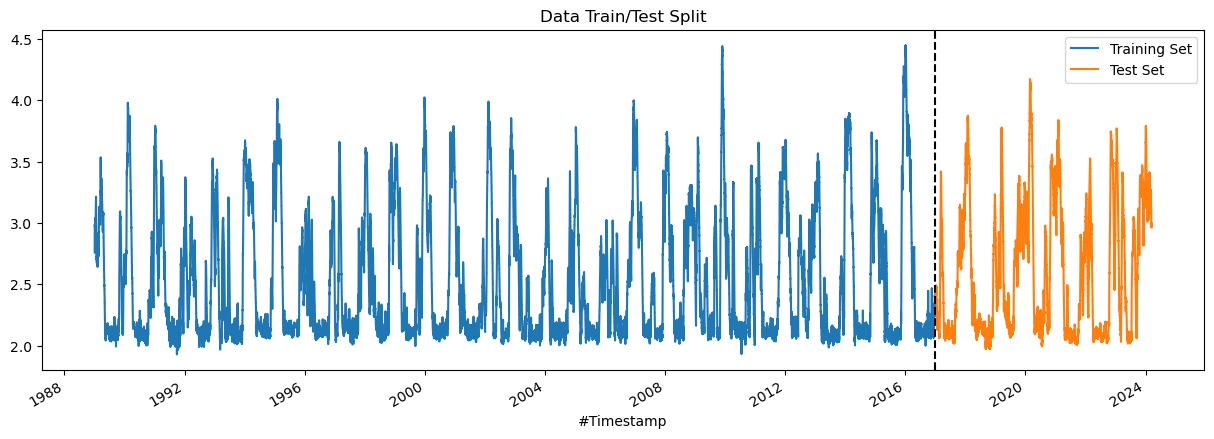

In [103]:
train = df.loc[df.index < '01-01-2017']
test = df.loc[df.index >= '01-01-2017']

fig, ax = plt.subplots(figsize=(15, 5))
train.plot(ax=ax, label='Training Set', title='Data Train/Test Split')
test.plot(ax=ax, label='Test Set')

ax.axvline('01-01-2017', color='black', ls='--')
ax.legend(['Training Set', 'Test Set'])
plt.show()


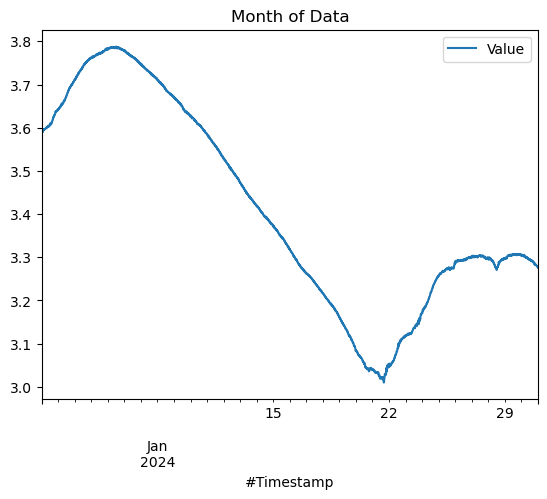

In [104]:
# weekly plot, or monthly
df.loc[(df.index > '01-01-2024') & (df.index <= '31-01-2024')].plot(title='Month of Data') 
plt.show()

# add the second graph here

### Feature Creation

In [105]:
df.index

DatetimeIndex(['1989-01-02 09:00:00+00:00', '1989-01-02 09:15:00+00:00',
               '1989-01-02 09:30:00+00:00', '1989-01-02 09:45:00+00:00',
               '1989-01-02 10:00:00+00:00', '1989-01-02 10:15:00+00:00',
               '1989-01-02 10:30:00+00:00', '1989-01-02 10:45:00+00:00',
               '1989-01-02 11:00:00+00:00', '1989-01-02 11:15:00+00:00',
               ...
               '2024-03-13 22:15:00+00:00', '2024-03-13 22:30:00+00:00',
               '2024-03-13 22:45:00+00:00', '2024-03-13 23:00:00+00:00',
               '2024-03-13 23:15:00+00:00', '2024-03-13 23:30:00+00:00',
               '2024-03-13 23:45:00+00:00', '2024-03-14 00:00:00+00:00',
               '2024-03-14 00:15:00+00:00', '2024-03-14 00:30:00+00:00'],
              dtype='datetime64[ns, UTC]', name='#Timestamp', length=1218710, freq=None)

In [113]:
def create_features(df):
    '''
    Create time series features based on time series index.
    '''
    df['hour'] = df.index.hour
    df['dayofweek'] = df.index.day_of_week
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.day_of_year
    return df

df = create_features(df)

# create a second more simple function?

In [114]:
df.head(25)

,Value,hour,dayofweek,quarter,month,year,dayofyear
#Timestamp,,,,,,,
1989-01-02 09:00:00+00:00,2.980,9,0,1,1,1989,2
1989-01-02 09:15:00+00:00,2.980,9,0,1,1,1989,2
1989-01-02 09:30:00+00:00,2.981,9,0,1,1,1989,2
1989-01-02 09:45:00+00:00,2.981,9,0,1,1,1989,2
1989-01-02 10:00:00+00:00,2.981,10,0,1,1,1989,2
1989-01-02 10:15:00+00:00,2.981,10,0,1,1,1989,2
1989-01-02 10:30:00+00:00,2.982,10,0,1,1,1989,2
1989-01-02 10:45:00+00:00,2.982,10,0,1,1,1989,2
1989-01-02 11:00:00+00:00,2.982,11,0,1,1,1989,2


### Visualise our feature / target relationship

Text(0.5, 1.0, 'Waterlevel in M')

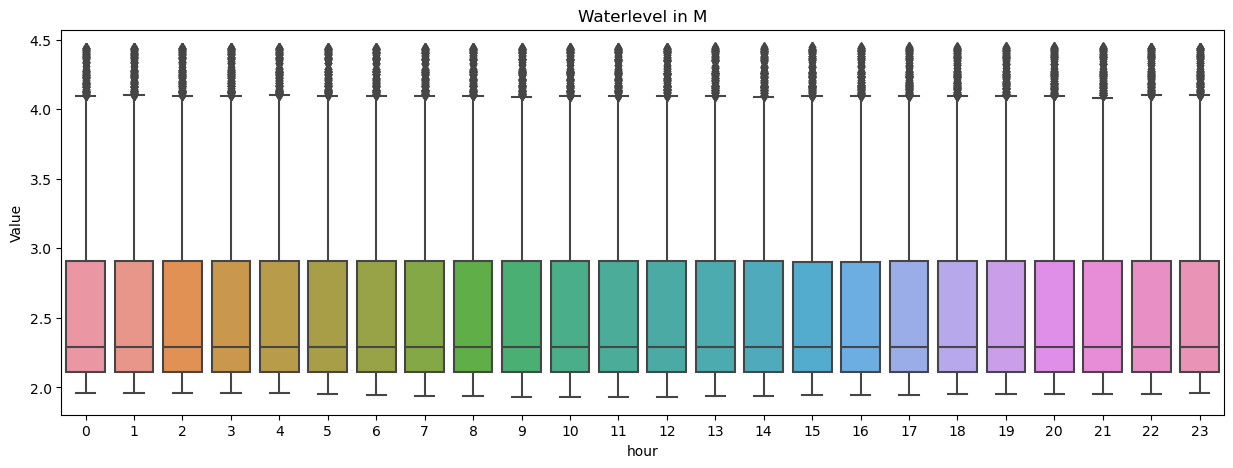

In [116]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(data=df, x='hour', y='Value')
ax.set_title('Waterlevel in M')
# this is trivial in this case, as waterlevel varies with slow cadence

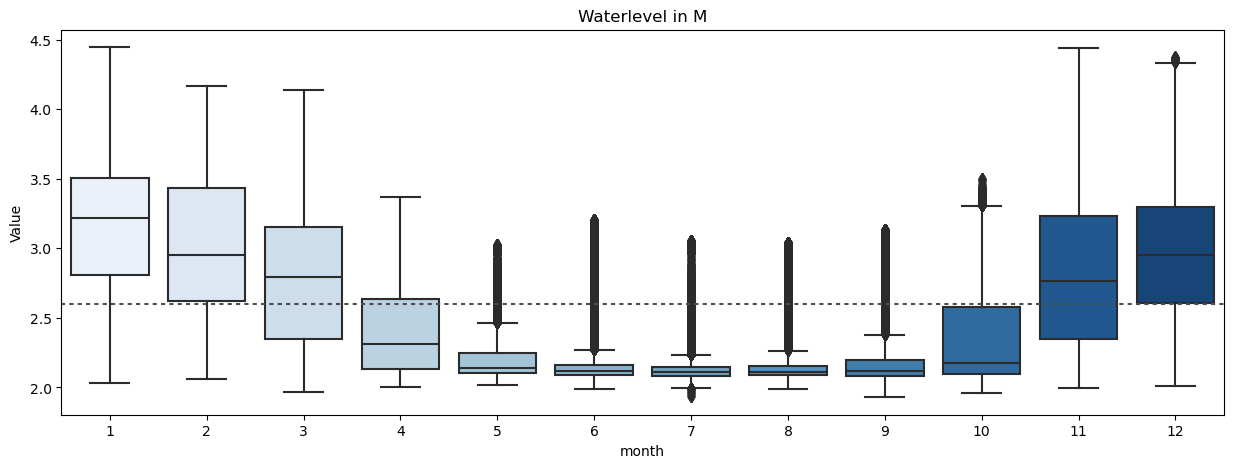

In [122]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(data=df, x='month', y='Value', palette='Blues')
ax.set_title('Waterlevel in M')
# I should put in the floodline here, for average projection of flooding in the future
# this is an absolute guess for first order approximation.
ax.axhline(2.6, color=".3", dashes=(2, 2))